In [1]:
import numpy as np
import os
os.environ['CUDA_VISIBLE_DEVICES'] = os.environ.get('CUDA_VISIBLE_DEVICES','0')
import torch

from alphagenome.data import genome
from alphagenome.models import dna_client
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.interpretation import ism
from alphagenome.models import dna_client
from alphagenome.models import variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd
from tangermeme.ersatz import dinucleotide_shuffle
from tangermeme.utils import one_hot_encode, characters, random_one_hot
from tangermeme.marginalize import marginalize
from tangermeme.ersatz import substitute
import random
from tqdm import tqdm
import time
from alphagenome.data import gene_annotation, genome, track_data, transcript
from alphagenome.models import dna_client
from alphagenome.visualization import plot_components
from tangermeme.io import extract_loci
from tqdm.auto import tqdm
from tangermeme.ablate import ablate
from tangermeme.ersatz import dinucleotide_shuffle
import seaborn; seaborn.set_style('whitegrid')
import grelu.resources
from utils import create_marginalization_sequence
from grelu.visualize import plot_ISM
from grelu.interpret import score



/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.27.2 is exactly one major version older than the runtime version 6.31.1 at alphagenome/protos/dna_model.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/google/protobuf/runtime_version.py:98: UserWarning: Protobuf gencode version 5.27.2 is exactly one major version older than the runtime version 6.31.1 at alphagenome/protos/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm a

In [2]:
grelu.resources.projects()

wandb: Currently logged in as: kobbad (kamalobbad) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


['tutorial-2',
 'decima',
 'human-mpra-gosai-2024',
 'GM12878_dnase',
 'demo',
 'human-mpra-agrawal-2023',
 'binary_atac_cell_lines',
 'model-zoo-test',
 'alzheimers-variant-tutorial',
 'microglia-scatac-tutorial',
 'human-chromhmm-fullstack',
 'human-atac-catlas',
 'borzoi',
 'yeast-gpra',
 'enformer']

In [3]:
grelu.resources.artifacts("enformer", type_is="model")


['mouse', 'human']

In [5]:
model = grelu.resources.load_model(
    project="enformer",
    model_name="human",
)


wandb: WARNING Serializing object of type list that is 277336 bytes
wandb: WARNING Serializing object of type list that is 277336 bytes
wandb: WARNING Serializing object of type list that is 277336 bytes
wandb: Downloading large artifact human:latest, 941.03MB. 1 files... 
wandb:   1 of 1 files downloaded.  
Done. 0:0:45.5 (20.7MB/s)


In [7]:
type(model)

grelu.lightning.LightningModel

todo:
1. find the cell types where OCT-SOX has a repressive effect (ideally fibroblast)
2. find example loci using ISM
3. Possibly compare to ChromBPNet?

In [8]:
model.data_params.keys()

dict_keys(['train', 'val', 'test', 'tasks'])

In [6]:
tasks = pd.DataFrame(model.data_params['tasks'])
tasks.head(3)

,name,file,clip,scale,sum_stat,description,assay,sample
0,ENCFF833POA,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:cerebellum male adult (27 years) and mal...,DNASE,cerebellum male adult (27 years) and male adul...
1,ENCFF110QGM,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:frontal cortex male adult (27 years) and...,DNASE,frontal cortex male adult (27 years) and male ...
2,ENCFF880MKD,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:chorion,DNASE,chorion


In [7]:
tasks.assay.value_counts()

assay
CHIP     3991
DNASE     674
CAGE      638
ATAC       10
Name: count, dtype: int64

In [8]:
dnase_mask = tasks.assay == "DNASE"
sum(dnase_mask), model.data_params["train"]["seq_len"]

(674, 196608)

In [12]:
hit_path = "/users/kobbad/feat_leakage/all_ap1_motifs/OCTSOX_FIMO_HITS/fimo.tsv"
motif_hits = pd.read_csv(hit_path, sep='\t').dropna()

In [13]:
first_quantile = motif_hits.score.quantile(0.25).item()
second_quantile = motif_hits.score.quantile(0.5).item()
third_quantile = motif_hits.score.quantile(0.75).item()

motif_list_first = np.unique(motif_hits[motif_hits.score <= first_quantile].matched_sequence.values)
motif_list_second = np.unique(motif_hits[(motif_hits.score > first_quantile) & (motif_hits.score <= second_quantile)].matched_sequence.values)
motif_list_third = np.unique(motif_hits[(motif_hits.score > second_quantile) & (motif_hits.score <= third_quantile)].matched_sequence.values)
motif_list_fourth = motif_list_first = np.unique(motif_hits[motif_hits.score > third_quantile].matched_sequence.values)

In [13]:
seq_len = model.data_params["train"]["seq_len"]
sequence_with_first_motif, sequence_with_first_shuffled = create_marginalization_sequence(400, motif_list_first, seq_len = seq_len)
sequence_with_second_motif, sequence_with_second_shuffled = create_marginalization_sequence(400, motif_list_second, seq_len = seq_len)
sequence_with_third_motif, sequence_with_third_shuffled = create_marginalization_sequence(400, motif_list_third, seq_len = seq_len)
sequence_with_fourth_motif, sequence_with_fourth_shuffled = create_marginalization_sequence(400, motif_list_fourth, seq_len = seq_len)

100%|██████████| 400/400 [00:22<00:00, 17.46it/s]


In [49]:
seqs_with_motif = sequence_with_fourth_motif
seqs_with_shuffled_motif = sequence_with_fourth_shuffled
seq_len = model.data_params["train"]["seq_len"]
dnase_mask = dnase_mask
metadata = tasks

motif_dataset = grelu.data.dataset.SeqDataset(seqs_with_motif, seq_len = seq_len)
shuffled_motif_dataset = grelu.data.dataset.SeqDataset(seqs_with_shuffled_motif, seq_len = seq_len)

In [15]:

preds_with_motif = model.predict_on_dataset(motif_dataset, devices=0, batch_size=12)
preds_with_shuffled_motif = model.predict_on_dataset(shuffled_motif_dataset, devices=0, batch_size=12)

# preds_with_motif = preds_with_motif[:, dnase_mask, :]
# preds_with_shuffled_motif = preds_with_shuffled_motif[:, dnase_mask, :]

preds_with_motif.shape, preds_with_shuffled_motif.shape

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]
/users/kobbad/anaconda3/envs/alphagenome

Predicting DataLoader 0: 100%|██████████| 27/27 [00:41<00:00,  0.66it/s]


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]


Predicting DataLoader 0: 100%|██████████| 27/27 [00:40<00:00,  0.67it/s]


((323, 5313, 896), (323, 5313, 896))

In [17]:
preds_with_motif = preds_with_motif[:, dnase_mask, :]
preds_with_shuffled_motif = preds_with_shuffled_motif[:, dnase_mask, :]

In [18]:
score = preds_with_motif.sum(axis=2) - preds_with_shuffled_motif.sum(axis=2)

score = score.mean(axis=0)

score.max(), score.min(), score.shape

(np.float32(0.0117890565), np.float32(-0.013091675), (674,))

In [23]:
metadata.iloc[np.argsort(score)[:10]]

,name,file,clip,scale,sum_stat,description,assay,sample
339,ENCFF399TJD,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:Daoy,DNASE,Daoy
594,ENCFF047HXB,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:spleen male adult (54 years),DNASE,spleen male adult (54 years)
625,ENCFF971AHO,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:K562,DNASE,K562
245,ENCFF414NAA,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:upper lobe of left lung male adult (37 y...,DNASE,upper lobe of left lung male adult (37 years)
185,ENCFF076JMD,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:RCC 7860,DNASE,RCC 7860
155,ENCFF438GIW,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:T-helper 2 cell male adult (33 years),DNASE,T-helper 2 cell male adult (33 years)
268,ENCFF340RUK,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:Peyer's patch male adult (54 years),DNASE,Peyer's patch male adult (54 years)
499,ENCFF361UTR,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:brain male embryo (122 days),DNASE,brain male embryo (122 days)
165,ENCFF989ALW,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:SK-N-DZ treated with dimethyl sulfoxide ...,DNASE,SK-N-DZ treated with dimethyl sulfoxide for 72...
68,ENCFF427FEF,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:GM12865,DNASE,GM12865


### We are going to try with the K562 cells

In [24]:
!wget https://www.encodeproject.org/files/ENCFF414OGC/@@download/ENCFF414OGC.bigWig
!wget https://www.encodeproject.org/files/ENCFF185XRG/@@download/ENCFF185XRG.bed.gz

--2025-08-11 22:37:16--  https://www.encodeproject.org/files/ENCFF414OGC/@@download/ENCFF414OGC.bigWig
Resolving www.encodeproject.org (www.encodeproject.org)... 34.211.244.144
Connecting to www.encodeproject.org (www.encodeproject.org)|34.211.244.144|:443... connected.
HTTP request sent, awaiting response... 307 Temporary Redirect
Location: https://encode-public.s3.amazonaws.com/2020/11/18/e5e1f67e-5af2-484a-b399-23bd39f2352d/ENCFF414OGC.bigWig?response-content-disposition=attachment%3B%20filename%3DENCFF414OGC.bigWig&AWSAccessKeyId=REDACTED&Signature=REDACTED&x-amz-security-token=REDACTED&Expires=1755081436 [following]
--2025-08-11 22:37:16--  https://encode-public.s3.amazonaws.com/2020/11/18/e5e1f67e-5af2-484a-b399-23bd39f2352d/ENCFF414OGC.bigWig?response-content-disposition=attachment%3B%20filename%3DENCFF414OGC.bigWig&AWSAccessKeyId=REDACTED&Signature=REDACTED&x-amz-security-token=REDACTED&Expires=1755081436
Resolving encode-public.s3.amazonaws.com (encode-public.s3.amazonaws.com)

In [27]:
hits = "/users/kobbad/feat_leakage/all_ap1_motifs/HNF4_run_8/fimo.tsv"
peaks = "/users/kobbad/feat_leakage/enformer_v2/ENCFF185XRG.bed.gz"

fasta = "/oak/stanford/groups/akundaje/jmschr/common/hg38/hg38.fa"

hits = pd.read_csv(hits, sep='\t')
peaks = pd.read_csv(peaks, sep='\t', header=None)

In [28]:
hits_chroms = hits[hits.sequence_name.astype(str).apply(lambda x: len(x)<=5).values]
hits_chroms.dropna(inplace=True)
hits_chroms['start'] = hits_chroms['start'].astype(int)
hits_chroms['stop'] = hits_chroms['stop'].astype(int)
hits_chroms.reset_index(drop=True, inplace=True)
hits_chroms.head()

hits_chroms.shape

/tmp/ipykernel_280108/729981416.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_chroms.dropna(inplace=True)
/tmp/ipykernel_280108/729981416.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_chroms['start'] = hits_chroms['start'].astype(int)
/tmp/ipykernel_280108/729981416.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-

(801223, 10)

In [29]:
peak_groups = {
    chrom: peaks[[1, 2, 9]].values # 9 is the peak summit
    for chrom, peaks in peaks.groupby(0)
}

# Preallocate result arrays
closest_peak_start = []
closest_peak_end = []
closest_peak_distance = []

for row in tqdm(hits_chroms.itertuples(), total=len(hits_chroms)):
    chrom = row.sequence_name
    start = row.start
    end = row.stop

    if chrom not in peak_groups:
        closest_peak_start.append(None)
        closest_peak_end.append(None)
        closest_peak_distance.append(None)
        continue

    peaks = peak_groups[chrom]
    # Vectorized computation: distance to start or end of each peak
    distances = np.minimum(np.abs((peaks[:,0]+peaks[:,2]) - start), np.abs((peaks[:,0]+peaks[:,2]) - end))
    #distances = np.minimum(np.abs(peaks[:, 0] - start), np.abs(peaks[:, 1] - start))
    min_idx = np.argmin(distances)

    closest_peak_start.append(peaks[min_idx, 0])
    closest_peak_end.append(peaks[min_idx, 1])
    closest_peak_distance.append(distances[min_idx])


100%|██████████| 801223/801223 [00:18<00:00, 44068.53it/s]


In [30]:
hits_chroms['closest_enhancer_start'] = closest_peak_start
hits_chroms['closest_enhancer_end'] = closest_peak_end
hits_chroms['distance'] = closest_peak_distance

hits_chroms.head()

/tmp/ipykernel_280108/2770698671.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_chroms['closest_enhancer_start'] = closest_peak_start
/tmp/ipykernel_280108/2770698671.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hits_chroms['closest_enhancer_end'] = closest_peak_end
/tmp/ipykernel_280108/2770698671.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: ht

,motif_id,motif_alt_id,sequence_name,start,stop,strand,score,p-value,q-value,matched_sequence,closest_enhancer_start,closest_enhancer_end,distance
0,MA0114.5,HNF4A,chr3,27159,27167,+,16.3546,0.000004,0.566,CAAAGTCCA,12044.0,12118.0,15040.0
1,MA0114.5,HNF4A,chr9,30054,30062,+,16.3546,0.000004,0.566,CAAAGTCCA,32452.0,32520.0,2465.0
2,MA0114.5,HNF4A,chr1,30276,30284,+,16.3546,0.000004,0.566,CAAAGTCCA,139369.0,139421.0,109160.0
3,MA0114.5,HNF4A,chr7,30675,30683,+,16.3546,0.000004,0.566,CAAAGTCCA,31420.0,31521.0,812.0
4,MA0114.5,HNF4A,chr2,36475,36483,-,16.3546,0.000004,0.566,CAAAGTCCA,18839.0,18901.0,17561.0


In [31]:
# get oct-sox motif hits within 200-500 bp of the peak summit
filt_hits_chroms = hits_chroms[(hits_chroms.distance > 200) & (hits_chroms.distance < 500)]
filt_hits_chroms.shape

(20971, 13)

In [64]:
filt_score = filt_hits_chroms.score.quantile(0.90).item()
filt_hits_chrom = filt_hits_chroms[filt_hits_chroms.score > filt_score]
filt_hits_chrom.shape

(1049, 13)

In [68]:
motif_length = 9
SEQ_LEN = seq_len


# format bed file for extracting hits
hits = filt_hits_chroms.filter(['sequence_name','start','stop']).reset_index(drop=True)
hits = hits.rename(columns={'sequence_name':'chromosome'})
hits = hits.rename(columns={'stop':'end'})
hits = hits.astype({'start':'int','end':'int'})
hits = hits.sample(500)

loci = extract_loci(hits, fasta, in_window = SEQ_LEN, verbose=True)

Loading Loci:   0%|          | 0/500 [00:00<?, ?it/s]

Loading Loci: 100%|██████████| 500/500 [00:00<00:00, 839.04it/s]


In [73]:
mask = loci.sum(axis=1).sum(axis=1) == seq_len
loci = loci[mask]
hits = hits.iloc[mask]

In [74]:
ablation_start = seq_len // 2 - 5
ablation_end = seq_len // 2 + 5

loci_ablated = dinucleotide_shuffle(loci, start = ablation_start, end = ablation_end, n=1).squeeze()

In [75]:
loci_str = [characters(loci[i]) for i in range(len(loci))]
loci_ablated_str = [characters(loci_ablated[i]) for i in range(len(loci_ablated))] 

In [76]:
loci_dataset = grelu.data.dataset.SeqDataset(loci_str, seq_len = seq_len)
loci_ablated_dataset = grelu.data.dataset.SeqDataset(loci_ablated_str, seq_len = seq_len)

In [77]:
preds_with_motif = model.predict_on_dataset(loci_dataset, devices=0, batch_size=12)
preds_with_shuffled_motif = model.predict_on_dataset(loci_ablated_dataset, devices=0, batch_size=12)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


Predicting DataLoader 0: 100%|██████████| 42/42 [01:02<00:00,  0.67it/s]


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]


Predicting DataLoader 0: 100%|██████████| 42/42 [01:01<00:00,  0.69it/s]


In [86]:
scores = preds_with_motif[:,dnase_mask,:] - preds_with_shuffled_motif[:,dnase_mask,:]
actual_scores = scores.sum(axis=2).sum(axis=0)
actual_scores.shape

(674,)

In [87]:
np.argsort(actual_scores)

array([163, 521, 117, 124,  54, 206, 450,   3, 589, 545, 114, 408, 216,
       232, 138, 144, 266, 133, 649, 387, 424, 353, 437, 118, 200, 561,
       471, 116, 125, 477, 508, 265,  76, 662, 464,  46, 179, 590, 295,
       142, 659,   5,   0, 267, 354,  60, 324, 421, 402, 167, 602, 512,
       241, 127, 380, 287, 618, 603, 249, 253, 180, 572, 617, 312, 376,
        89, 320, 631, 302, 100, 500, 261, 108,  80, 576, 427, 326, 557,
       646, 343, 195, 364, 191, 670, 478, 465, 457, 310,  28,  42, 619,
       635, 528, 107, 569, 655, 317, 333, 101, 105, 527, 434,  82, 341,
       230, 299, 157, 609,  77, 406, 313, 520, 581, 221, 115, 260, 633,
       467, 647, 441, 517, 146, 181, 385, 426,  95, 322,  78, 574, 585,
       462, 511, 213, 339, 663, 599, 390, 481, 391, 615,  56, 171, 616,
       591, 400, 433, 664,  25,  31,  66, 600, 187, 314, 630, 208, 560,
       577, 358, 502, 366, 476, 669, 245, 510, 342, 555, 327,  30, 384,
       396, 132, 656, 438, 351,  29,  41, 394, 607, 605, 378, 57

In [95]:
task_idx = 117
(preds_with_motif[:,task_idx,:] - preds_with_shuffled_motif[:,task_idx,:]).sum(axis=1).mean()

np.float32(-0.023631303)

In [96]:
tasks.iloc[task_idx]

name                                                 ENCFF684FJC
file           /home/drk/tillage/datasets/human/dnase/encode/...
clip                                                          32
scale                                                          2
sum_stat                                                    mean
description    DNASE:myotube originated from skeletal muscle ...
assay                                                      DNASE
sample          myotube originated from skeletal muscle myoblast
Name: 117, dtype: object

### Run ablations and find negative OCT-SOX motifs

In [9]:
hit_path = "/users/kobbad/feat_leakage/all_ap1_motifs/OCTSOX_FIMO_HITS/fimo.tsv"
motif_hits = pd.read_csv(hit_path, sep='\t').dropna()

In [10]:
motif_90_quantile = motif_hits.score.quantile(0.85).item()
motif_hits = motif_hits[motif_hits.score > motif_90_quantile]
motif_hits = motif_hits[motif_hits.sequence_name.astype(str).apply(lambda x: len(x)<=5).values]
motif_hits.shape

(9353, 10)

In [15]:
SEQ_LEN

196608

In [11]:
fasta = "/oak/stanford/groups/akundaje/jmschr/common/hg38/hg38.fa"
SEQ_LEN = model.data_params['train']['seq_len']


# format bed file for extracting hits
filt_hits_chroms = motif_hits
hits = filt_hits_chroms.filter(['sequence_name','start','stop']).reset_index(drop=True)
hits = hits.rename(columns={'sequence_name':'chromosome'})
hits = hits.rename(columns={'stop':'end'})
hits = hits.astype({'start':'int','end':'int'})
hits = hits.sample(1000)

loci = extract_loci(hits, fasta, in_window = SEQ_LEN, verbose=True)
loci.shape

Loading Loci: 100%|██████████| 1000/1000 [00:01<00:00, 859.74it/s]


torch.Size([1000, 4, 196608])

In [12]:
mask = loci.sum(axis=1).sum(axis=1) == SEQ_LEN
loci = loci[mask]
hits = hits.iloc[mask.numpy()]

In [13]:
hits.shape, loci.shape

((986, 3), torch.Size([986, 4, 196608]))

In [14]:
ablation_start = SEQ_LEN // 2 - 7
ablation_end = SEQ_LEN // 2 + 7

loci_ablated = dinucleotide_shuffle(loci, start = ablation_start, end = ablation_end, n=1).squeeze()

In [16]:
loci_str = [characters(loci[i]) for i in range(len(loci))]
loci_ablated_str = [characters(loci_ablated[i]) for i in range(len(loci_ablated))] 

In [17]:
loci_dataset = grelu.data.dataset.SeqDataset(loci_str, seq_len = SEQ_LEN)
loci_ablated_dataset = grelu.data.dataset.SeqDataset(loci_ablated_str, seq_len = SEQ_LEN)

In [18]:
preds_with_motif = model.predict_on_dataset(loci_dataset, devices=0, batch_size=12)
preds_with_shuffled_motif = model.predict_on_dataset(loci_ablated_dataset, devices=0, batch_size=12)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]
/users/kobbad/anaconda3/envs/alphagenome

Predicting DataLoader 0: 100%|██████████| 83/83 [02:01<00:00,  0.68it/s]


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]


Predicting DataLoader 0: 100%|██████████| 83/83 [02:01<00:00,  0.68it/s]


In [19]:
scores = preds_with_motif[:,dnase_mask,:] - preds_with_shuffled_motif[:,dnase_mask,:]
actual_scores = scores.sum(axis=2).sum(axis=0)

In [23]:
actual_scores.argsort()

array([135, 235, 158, 288, 147,  58, 449, 136, 361, 110,  79, 352, 623,
       497, 451, 321,  98, 434, 254, 115, 263, 620, 196, 238,  52, 119,
       375, 349, 332,  65, 423, 328, 273, 424, 356, 504, 484,  64, 111,
       506, 435, 275, 415, 570, 642,  95, 186, 230, 443, 343, 520, 391,
       266, 318, 313, 256, 538, 605,  55, 250, 301, 253, 276, 536, 365,
       378, 363, 646, 180, 668, 633, 320, 324, 571,  93, 213,  50, 405,
       116, 500, 609, 160, 249,  92, 159, 551,  94, 385, 426, 358,  51,
        56, 478, 384, 516, 195, 404, 181, 310, 523, 525,  87, 299, 581,
       284, 483,  53, 191, 312, 247,  48, 344, 647, 309,  35, 267, 317,
       341, 442, 231, 142,  86, 342, 327, 649,   6, 590, 560, 615, 199,
       182, 450, 568, 192, 167,  33,  63, 541, 302, 260, 603, 635, 433,
       393, 490, 336, 591, 364, 463, 512, 125, 533, 468, 387, 634, 410,
       413, 169, 655, 223, 314, 396, 295, 282, 618,  34, 407,  85, 272,
       200, 645, 632, 498, 519, 165, 625, 432, 226, 400, 251, 59

In [25]:
tasks.iloc[np.argsort(actual_scores)[:10]]

,name,file,clip,scale,sum_stat,description,assay,sample
135,ENCFF302JEV,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:fibroblast of dermis female adult,DNASE,fibroblast of dermis female adult
235,ENCFF366GCX,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:foreskin fibroblast male newborn,DNASE,foreskin fibroblast male newborn
158,ENCFF369NZI,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:WERI-Rb-1,DNASE,WERI-Rb-1
288,ENCFF113YFF,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:foreskin fibroblast male newborn,DNASE,foreskin fibroblast male newborn
147,ENCFF627SBE,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:skeletal muscle cell,DNASE,skeletal muscle cell
58,ENCFF747REW,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:stromal cell of bone marrow male,DNASE,stromal cell of bone marrow male
449,ENCFF660PED,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:skin fibroblast male embryo (97 days),DNASE,skin fibroblast male embryo (97 days)
136,ENCFF861ULS,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:foreskin fibroblast male newborn,DNASE,foreskin fibroblast male newborn
361,ENCFF851MCI,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:heart male embryo (120 days),DNASE,heart male embryo (120 days)
110,ENCFF519CAJ,/home/drk/tillage/datasets/human/dnase/encode/...,32,2,mean,DNASE:fibroblast of peridontal ligament male,DNASE,fibroblast of peridontal ligament male


In [26]:
# fibroblast of female dermis (ENCFF302JEV)
!wget https://www.encodeproject.org/files/ENCFF184KAM/@@download/ENCFF184KAM.bed.gz
!wget https://www.encodeproject.org/files/ENCFF361BTT/@@download/ENCFF361BTT.bigWig

--2025-08-12 16:21:03--  https://www.encodeproject.org/files/ENCFF184KAM/@@download/ENCFF184KAM.bed.gz
Resolving www.encodeproject.org (www.encodeproject.org)... 34.211.244.144
Connecting to www.encodeproject.org (www.encodeproject.org)|34.211.244.144|:443... connected.
HTTP request sent, awaiting response... 307 Temporary Redirect
Location: https://encode-public.s3.amazonaws.com/2020/11/18/4f5d0e67-0567-4520-8630-fb2302b2a953/ENCFF184KAM.bed.gz?response-content-disposition=attachment%3B%20filename%3DENCFF184KAM.bed.gz&AWSAccessKeyId=REDACTED&Signature=REDACTED&x-amz-security-token=REDACTED&Expires=1755145267 [following]
--2025-08-12 16:21:07--  https://encode-public.s3.amazonaws.com/2020/11/18/4f5d0e67-0567-4520-8630-fb2302b2a953/ENCFF184KAM.bed.gz?response-content-disposition=attachment%3B%20filename%3DENCFF184KAM.bed.gz&AWSAccessKeyId=REDACTED&Signature=REDACTED&x-amz-security-token=REDACTED&Expires=1755145267
Resolving encode-public.s3.amazonaws.com (encode-public.s3.amazonaws.com)

In [ ]:
fibroblast_bed_file = "/users/kobbad/feat_leakage/enformer_v2/ENCFF184KAM.bed.gz"
motif_hits = "/users/kobbad/feat_leakage/all_ap1_motifs/OCTSOX_FIMO_HITS/fimo.tsv"



In [33]:
hits_with_distance = annotate_with_peak_distances(motif_hits, fibroblast_bed_file)

/tmp/ipykernel_358375/2300183079.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  oct_sox_chroms.dropna(inplace=True)
/tmp/ipykernel_358375/2300183079.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  oct_sox_chroms['start'] = oct_sox_chroms['start'].astype(int)
/tmp/ipykernel_358375/2300183079.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#re

In [34]:
hits_with_distance.head()

,motif_id,motif_alt_id,sequence_name,start,stop,strand,score,p-value,q-value,matched_sequence,closest_enhancer_start,closest_enhancer_end,distance
0,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr9,2018958,2018970,+,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,2017860,2018300,1023
1,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr7,3281165,3281177,+,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,3280620,3280820,470
2,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr12,3798659,3798671,+,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,3802625,3802776,4029
3,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chr8,3908225,3908237,-,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,3764304,3764380,143846
4,"AC0636:POU5F/NANOG:Homeodomain,POU","AC0636:POU5F/NANOG:Homeodomain,POU",chrX,4530392,4530404,+,18.6364,2.790000e-08,0.385,ATTGTTATGCAAA,4547340,4547500,17011


In [54]:
motif_90_quantile = hits_with_distance.score.quantile(0.85).item()
motif_hits = hits_with_distance[hits_with_distance.score > motif_90_quantile]
motif_hits = hits_with_distance[hits_with_distance.sequence_name.astype(str).apply(lambda x: len(x)<=5).values]
motif_hits.shape

(64256, 13)

In [55]:
# distance < 5000 from peak
motif_hits = motif_hits[motif_hits.distance < 5000]
motif_hits.shape

(29060, 13)

In [57]:
preds_with_motif, preds_with_ablated_motif, hits_sampled = ablate_motifs(motif_hits, model, motif_length = 14)

Loading Loci:   0%|          | 0/1000 [00:00<?, ?it/s]

Loading Loci: 100%|██████████| 1000/1000 [00:01<00:00, 879.58it/s]
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


Predicting DataLoader 0: 100%|██████████| 83/83 [02:03<00:00,  0.67it/s]


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]


Predicting DataLoader 0: 100%|██████████| 83/83 [02:02<00:00,  0.68it/s]


In [58]:
dnase_preds = preds_with_motif[:, dnase_mask,:]
dnase_preds_ablated = preds_with_ablated_motif[:, dnase_mask,:]

dnase_preds.shape, dnase_preds_ablated.shape

((996, 674, 896), (996, 674, 896))

In [59]:
motif_scores = dnase_preds - dnase_preds_ablated
motif_scores_per_task = motif_scores.sum(axis=2).mean(axis=0)

In [68]:
np.argsort(motif_scores[:, 135,:].mean(axis=1))

array([952, 885, 578, 772, 231, 725, 750, 266, 334, 216, 506, 987, 866,
       809, 244,  46, 221, 317, 194,  32, 246, 699, 792, 135, 229, 846,
       399, 529, 606, 432, 571,  56, 526, 245, 520, 915, 732, 819, 756,
       925, 608, 149, 637, 304, 662, 984, 141, 485, 768,  41, 992, 412,
       474, 749, 204, 703, 647, 273, 134, 899, 752, 239, 507, 939, 911,
       482, 343, 664, 346, 280, 901, 275, 797, 545, 958, 655, 308, 710,
       565, 976, 365, 627, 490, 303, 296, 269, 283, 626,   6, 326, 446,
       394, 907,  37, 421, 942, 430, 227, 660, 451, 497, 413, 783, 547,
       593, 433, 553, 153, 154, 536, 757, 887, 983,  62, 352, 390, 572,
       928, 918, 583, 956, 898, 631, 104, 708, 188, 778, 309, 970, 667,
       882,  94, 642, 492, 176, 766, 249, 897, 670,  91, 585, 289, 445,
       935, 550, 351, 375, 307, 376,  50, 769, 559, 877, 679, 644, 272,
       354, 522, 781, 623, 971, 950, 179, 157, 505, 513, 824, 678, 142,
       790, 187,  42, 951, 335, 685, 405, 607, 870, 211, 648, 86

In [147]:
chrom, start, end = hits_sampled.iloc[266]
motif = motif_hits.loc[(motif_hits['sequence_name'] == chrom) & (motif_hits['start'] == start) & (motif_hits['stop'] == end)].matched_sequence.values[0]

seq = extract_loci(pd.DataFrame({'chromosome':[chrom], 'start':[start], 'end':[end]}), fasta, in_window = SEQ_LEN, verbose=True).squeeze()
seq_str = characters(seq)

Loading Loci: 100%|██████████| 1/1 [00:00<00:00, 221.99it/s]


In [148]:

predict_transform = grelu.transforms.prediction_transforms.Aggregate([135], length_aggfunc = 'sum', model=model)

start_pos = SEQ_LEN // 2 - 50
end_pos = SEQ_LEN // 2 + 50
compare_func = "log2FC"
devices = 0
batch_size = 12
return_df = True

ism_score = interpret.score.ISM_predict(
    seqs = seq_str,
    model = model,
    prediction_transform = predict_transform,
    devices = devices,
    batch_size = batch_size,
    num_workers = 1, 
    start_pos = start_pos,
    end_pos = end_pos,
    compare_func = compare_func,
    return_df = return_df,
)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: PossibleUserWarning: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


Predicting DataLoader 0: 100%|██████████| 34/34 [00:46<00:00,  0.73it/s]


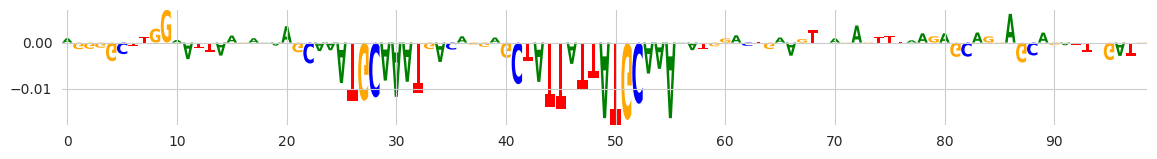

In [149]:
plot_ISM(ism_score, method="logo", figsize=(14, 1.5))

In [150]:
print(f"{chrom}:{start}-{end}")

chr5:115472525-115472537


In [156]:
out_window = dnase_preds[266, 135, :].shape[0]

In [161]:
bigwig_path = "/users/kobbad/feat_leakage/enformer_v2/ENCFF361BTT.bigWig"

locus = pd.DataFrame({'chrom':[chrom], 'start':[start], 'end':[end]})

locus, signal = extract_loci(locus, fasta, [bigwig_path],out_window=out_window * 128, in_window = SEQ_LEN, verbose=True)

locus.shape, signal.shape

Loading Loci: 100%|██████████| 1/1 [00:00<00:00, 48.68it/s]


(torch.Size([1, 4, 196608]), torch.Size([1, 1, 114688]))

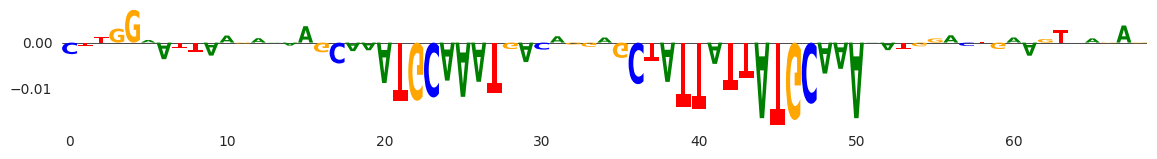

In [194]:
plot_ISM(ism_scores[7], method="logo", start_pos = 5, end_pos = 75,figsize=(14, 1.5))
# Save as PDF
plt.savefig('ism_plot.pdf', format='pdf', bbox_inches='tight', dpi=300)

# Save as SVG
plt.savefig('ism_plot.svg', format='svg', bbox_inches='tight')

# Display the plot
plt.show()

In [189]:
_, actual_profile = extract_loci(pd.DataFrame({"chrom": [chrom], 
                                            "start": [start], 
                                            "end":[end]}, 
                                           index=None), 
                                           fasta, 
                                           signals=[bigwig_path],
                                           in_window = SEQ_LEN, 
                                           out_window=out_window * 128, 
                                           verbose=True)
actual_values = actual_profile.squeeze().numpy()[:,np.newaxis]
actual_metadata = pd.DataFrame({"name": ["actual"], "strand": ["+"]})

interval = genome.Interval(chrom, start, end).resize(out_window * 128)

actual_track_data = track_data.TrackData(actual_values,
                                         actual_metadata,
                                         interval = interval)


expanded_prediction = np.repeat(dnase_preds[266, 135, :], 128).squeeze()[:,np.newaxis]
predicted_metadata = pd.DataFrame({"name": ["predicted"], "strand": ["+"]})
predicted_track_data = track_data.TrackData(expanded_prediction,
                                            predicted_metadata,
                                            interval = interval)


Loading Loci: 100%|██████████| 1/1 [00:00<00:00, 141.18it/s]


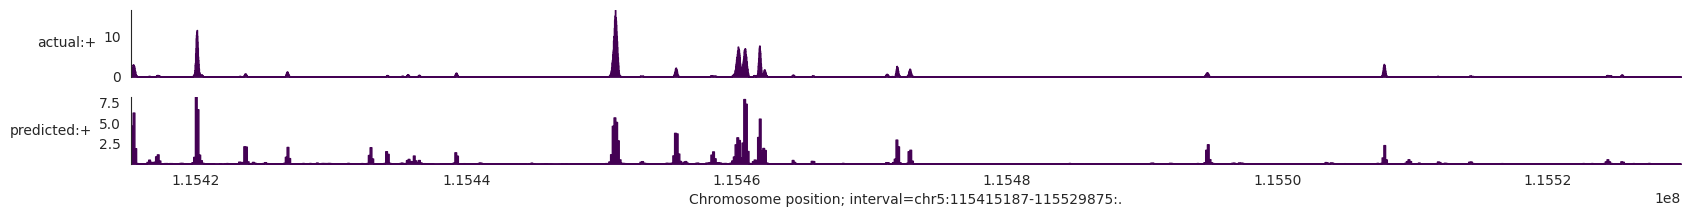

In [193]:
import seaborn as sns
sns.set_style("white")  
plot_components.plot(
    components=[
        plot_components.Tracks(actual_track_data, filled=True),
        plot_components.Tracks(predicted_track_data, filled=True),
    ],
    interval=interval,
)
# Save as SVG and PDF
plt.savefig('profile_plot.svg', format='svg', bbox_inches='tight')
plt.savefig('profile_plot.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [183]:
dnase_preds[266, 135, :].shape

(896,)

In [185]:
np.repeat(dnase_preds[266, 135, :], 128).shape

(114688,)

### Perform the ablation experiment

In [197]:
# get oct-sox motif hits within 200-500 bp of the peak summit
motif_hits_filt = motif_hits[motif_hits.distance.between(200, 500)]
motif_hits_filt.shape

(2955, 13)

In [200]:
preds_with_motif, preds_with_ablated_motif, hits_sampled = ablate_motifs(motif_hits, model, motif_length = 14, num_loci = 500, seq_len = SEQ_LEN)

Loading Loci: 100%|██████████| 500/500 [00:15<00:00, 33.00it/s]
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]
/users/kobbad/anaconda3/envs/alphagenome-env/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:425: PossibleUserWarning: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader` to improve performance.


Predicting DataLoader 0: 100%|██████████| 42/42 [01:03<00:00,  0.66it/s]


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [GPU-923aa602-92cb-7054-0605-b50ebabdc322]


Predicting DataLoader 0: 100%|██████████| 42/42 [01:01<00:00,  0.68it/s]


In [ ]:
fig, ax = plt.subplots(figsize=(2,4))
ax.boxplot([oct_sox_ablation_strength, oct_sox_marginalization_strength],
            labels = ['Ablation', 'Marginalization'], 
            showfliers=False,
            widths=0.5,
            patch_artist=True,
            boxprops=dict(facecolor='lightgray', color='black'),
            medianprops=dict(color='black'));
plt.xticks(rotation=45, ha='right')

# Save as SVG
fig.savefig('boxplot.svg', format='svg', bbox_inches='tight', dpi=300)
plt.show()

In [201]:
dnase_preds = preds_with_motif[:, dnase_mask,:]
dnase_preds_ablated = preds_with_ablated_motif[:, dnase_mask,:]

dnase_preds.shape, dnase_preds_ablated.shape

((497, 674, 896), (497, 674, 896))

In [205]:
score = dnase_preds[:,135,:] - dnase_preds_ablated[:,135,:]
score.sum(axis=1).mean()

np.float32(0.008591667)